# Experiment 2: does the model's edge hold up month after month?

**From the diagnosis:**
- **Cross-validation** says the team model beats "exploit code then EPSS" by +13 in the top 442. But cross-validation mixes the years: it trains on 2025 rows to score 2024 rows.
- **The honest forward check** (train 2024 → test 2025) gives only **+5 (90% range −1 to +10)**, which isn't significant.
- **On May-September 2025**, the model barely beat the baseline (9 vs. 8).

**Hypothesis:** the model's advantage shrinks in recent months (drift: the March 2025 EPSS model change, VulnCheck's surge of new IDs for old bugs, NIST's backlog). If so, cross-validation overstates what the 2026 list will gain.

**The test: a rolling origin, run the way a security team would actually use the model.**
- **Origins:** each month *m* from July-September 2024 and January-September 2025 (12 test months).
- **Training:** every CVE with a snapshot **before** *m*, labeled using **only KEV additions dated before the first day of *m***, i.e. what was known at the time. *Example:* at the March 2025 origin, a CVE from November 2024 that CISA added in April 2025 counts as **not** exploited, because nobody knew yet.
- **Testing:** the CVEs published in month *m*, with the Phase 3 label (added after the publish month and by December 31 of that year).
- **Scoring:** the top 0.69% of each test month (the benchmark's share), with hits summed over all 12 months.

**Rankings compared:** the team blend (current), LR alone, LightGBM alone, the baseline, and Experiment 1's pruned variants P1 and P2.

**Decision rule, fixed in advance:**
- **The edge is real and stable:** the pooled advantage over the baseline has a 90% lower bound above 0, **and** the January-September 2025 origins still show a positive advantage.
- **Drift confirmed:** the advantage for the July-September 2025 origins is ≤ 0. Then the 2026 list should lean on the baseline where the model adds nothing.

## Setup: every CVE from January 2024 to September 2025, with point-in-time features

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = next(p for p in [Path(".."), Path(".")] if (p / "ml" / "config.py").exists()).resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, lightgbm as lgb
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from ml import data
from ml.featureset import FeatureBuilder
pd.set_option("display.width", 220)
BLUE, ORANGE, INK, INK2, SURF = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left", "font.size": 10,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "figure.dpi": 110, "legend.frameon": False})

con = data.connect()
# Labels here use the year-end deadline; per-origin training labels are rebuilt from kev_date below.
rows24 = data.labeled_rows(con, "2024-01-01", "2024-12-31", "2024-12-31", "exploit_signals_2024")
rows25 = data.labeled_rows(con, "2025-01-01", "2025-09-30", "2025-12-31", "exploit_signals_2025")
fb = FeatureBuilder(con)
ALL = fb.transform(pd.concat([rows24, rows25], ignore_index=True).sort_values("cve_id").reset_index(drop=True))
ALL["kev_date"] = pd.to_datetime(ALL["kev_date"]); ALL["snap_start"] = pd.to_datetime(ALL["snap"] + "-01")
print(f"{len(ALL):,} CVEs, snapshots {ALL.snap.min()} to {ALL.snap.max()}")

BASE = ["any_exploit", "poc_github", "nuclei", "log_assigner_kev_rate", "kw_unauth", "pr_none", "ui_none", "cvss_filled", "cwe_auth", "cwe_path"]
NEW4 = ["net_preauth", "log_batch_size", "log_cwe_kev_rate", "product_has_kev"]
NEAR_ZERO = ["pr_none", "net_preauth", "log_cwe_kev_rate", "product_has_kev", "cwe_auth", "cwe_path"]
drop = lambda cols, out: [c for c in cols if c not in out]
VARIANTS = {"Current blend": (BASE, BASE + NEW4),
            "P1: - CVSS": (drop(BASE, ["cvss_filled"]), drop(BASE + NEW4, ["cvss_filled"])),
            "P2: - CVSS - 6 near-zero": (drop(BASE, ["cvss_filled"] + NEAR_ZERO), drop(BASE + NEW4, ["cvss_filled"] + NEAR_ZERO))}
GBM = dict(n_estimators=200, learning_rate=0.03, num_leaves=4, max_depth=2, min_child_samples=40, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, reg_lambda=5, scale_pos_weight=50, verbose=-1)

75,149 CVEs, snapshots 2024-01 to 2025-09


## Run the 12 origins

LightGBM is averaged over 10 seeds at each origin. The training labels are rebuilt from the KEV dates for every origin.

In [2]:
ORIGINS = ["2024-07", "2024-08", "2024-09"] + [f"2025-{m:02d}" for m in range(1, 10)]
results, scored = [], []
for m in ORIGINS:
    start = pd.Timestamp(m + "-01")
    A = ALL[ALL.snap_start < start].copy()
    A["y"] = (A.kev_date.notna() & (A.kev_date < start)).astype(int)        # only what was known at the origin
    B = ALL[ALL.snap == m].copy()                                           # test month, Phase 3 labels
    out = {"origin": m, "train rows": len(A), "train positives (known then)": int(A.y.sum()),
           "test rows": len(B), "test positives": int(B.y.sum()), "k": int(round(len(B) * 0.0069))}
    sc = {"Baseline": (B.any_exploit * 10 + B.epss.fillna(0)).values}
    for v, (c_lr, c_gb) in VARIANTS.items():
        p_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)).fit(A[c_lr], A.y).predict_proba(B[c_lr])[:, 1]
        p_gb = np.mean([lgb.LGBMClassifier(**GBM, random_state=s).fit(A[c_gb], A.y).predict_proba(B[c_gb])[:, 1] for s in range(10)], axis=0)
        sc[v] = 0.5 * rankdata(p_lr) + 0.5 * rankdata(p_gb)
        if v == "Current blend":
            sc["LR alone"], sc["LightGBM alone"] = p_lr, p_gb
    for name, s in sc.items():
        out[name] = int(B.y.values[np.argsort(-s, kind="stable")[:out["k"]]].sum())
    results.append(out)
    scored.append((m, B.y.values, sc, out["k"]))
res = pd.DataFrame(results).set_index("origin")
res

,train rows,train positives (known then),test rows,test positives,k,Baseline,Current blend,LR alone,LightGBM alone,P1: - CVSS,P2: - CVSS - 6 near-zero
origin,,,,,,,,,,,
2024-07,20341,6,3105,2,21,0,0,0,0,0,0
2024-08,23446,10,2885,5,20,1,2,2,0,2,3
2024-09,26331,13,2508,5,17,0,1,0,1,1,2
2025-01,39868,40,4267,7,29,1,2,5,2,5,5
2025-02,44135,43,3664,6,25,1,2,2,1,1,1
2025-03,47799,54,3982,7,27,2,3,3,4,4,4
2025-04,51781,63,4024,5,28,3,3,3,2,2,2
2025-05,55805,67,3968,6,27,2,3,3,3,4,4
2025-06,59773,77,3674,8,25,3,3,1,3,2,3


**Reading this:**
- **Realistic training labels are scarce:** at the July 2024 origin, only 6 positives were known; even by September 2025, only 95.
- **Each test month holds only 2-8 exploited CVEs,** so single months are very noisy, and only the pooled totals below mean much.

## Pooled results, with a paired bootstrap

Rows are resampled **within each test month**, so every resample keeps the monthly structure. Each ranking's per-month top-k hits are recounted and summed. We report the totals, and each ranking's difference from the baseline.

In [3]:
names = ["Current blend", "LR alone", "LightGBM alone", "P1: - CVSS", "P2: - CVSS - 6 near-zero", "Baseline"]
rng = np.random.default_rng(0); NB = 2000
boot = {n: np.zeros(NB) for n in names}
for m, y, sc, k in scored:
    ranks = {n: rankdata(-sc[n], method="ordinal") for n in names}
    for b in range(NB):
        i = rng.integers(0, len(y), len(y))
        for n in names:
            boot[n][b] += y[i][np.argpartition(ranks[n][i], k)[:k]].sum()
def period(mask_months):
    sub = res.loc[[m for m in res.index if mask_months(m)]]
    return sub
tot = res[names].sum()
summary = pd.DataFrame({"pooled hits (12 months)": tot,
                        "of positives": int(res["test positives"].sum()),
                        "vs. baseline": [f"{tot[n] - tot['Baseline']:+d} ({np.quantile(boot[n] - boot['Baseline'], .05):+.0f} to "
                                         f"{np.quantile(boot[n] - boot['Baseline'], .95):+.0f})" if n != "Baseline" else "" for n in names],
                        "2024 Q3 origins": period(lambda m: m.startswith("2024"))[names].sum(),
                        "2025 Jan-Jun": period(lambda m: "2025-01" <= m <= "2025-06")[names].sum(),
                        "2025 Jul-Sep": period(lambda m: m >= "2025-07")[names].sum()})
summary

,pooled hits (12 months),of positives,vs. baseline,2024 Q3 origins,2025 Jan-Jun,2025 Jul-Sep
Current blend,22,64,+6 (+0 to +12),3,16,3
LR alone,22,64,+6 (+0 to +13),2,17,3
LightGBM alone,22,64,+6 (-1 to +12),1,15,6
P1: - CVSS,24,64,+8 (+2 to +16),3,18,3
P2: - CVSS - 6 near-zero,27,64,+11 (+3 to +18),5,19,3
Baseline,16,64,,1,12,3


**Reading this:**
- **Over 12 strictly time-ordered months** (64 exploited CVEs), the current blend finds **22** against the baseline's **16**: **+6, 90% range +0 to +12**. That's about 40% more, but the lower bound sits right at 0, so the edge is real but modest.
- **That's well below cross-validation's +13,** which mixes years and is the optimistic estimate.
- **The edge comes from early 2025** (16 vs. 12 in January-June). **In July-September 2025, model and baseline tie (3 vs. 3).**
- **Logistic regression alone and LightGBM alone also score 22,** so in this test the blend's advantage over its parts disappears.

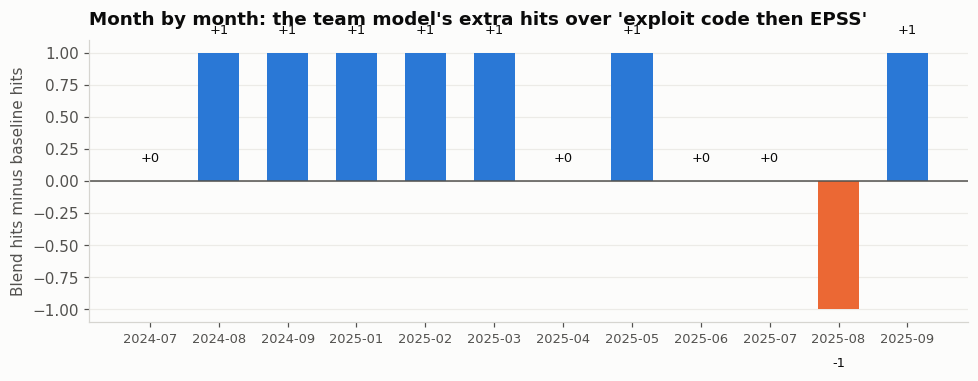

In [4]:
diff = res["Current blend"] - res["Baseline"]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(diff)), diff.values, color=[BLUE if d > 0 else (ORANGE if d < 0 else "#b9b8b2") for d in diff.values], width=0.6)
ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(len(diff)), diff.index, rotation=0, fontsize=8.5); ax.grid(axis="x", visible=False)
for i, (d, p) in enumerate(zip(diff.values, res["test positives"].values)):
    ax.text(i, d + (0.15 if d >= 0 else -0.45), f"{d:+d}", ha="center", fontsize=8.5, color=INK)
ax.set_ylabel("Blend hits minus baseline hits")
ax.set_title("Month by month: the team model's extra hits over 'exploit code then EPSS'", pad=10)
plt.tight_layout(); plt.show()

### The pruned variants vs. the current model, paired

The same resamples, read differently: each pruned variant's pooled hits minus the current blend's. This settles whether pruning helps in this strictly time-ordered test.

In [5]:
for n in ["P1: - CVSS", "P2: - CVSS - 6 near-zero", "LR alone", "LightGBM alone"]:
    d = boot[n] - boot["Current blend"]
    print(f"{n:26} vs. current blend: {tot[n] - tot['Current blend']:+d} (90% range {np.quantile(d, .05):+.0f} to {np.quantile(d, .95):+.0f}), "
          f"share of resamples where it wins: {(d > 0).mean():.0%}")

P1: - CVSS                 vs. current blend: +2 (90% range -2 to +8), share of resamples where it wins: 79%
P2: - CVSS - 6 near-zero   vs. current blend: +5 (90% range -1 to +10), share of resamples where it wins: 88%
LR alone                   vs. current blend: +0 (90% range -4 to +5), share of resamples where it wins: 49%
LightGBM alone             vs. current blend: +0 (90% range -6 to +5), share of resamples where it wins: 40%


**Reading this:** the pruned variants point upward but aren't proven. P2 is +5 against the current blend (range −1 to +10; it wins in 88% of resamples), and P1 +2 (−2 to +8). Experiment 1's cross-validation pointed the other way (P2 −3). **Two different tests, both inconclusive, in opposite directions,** so pruning stays unadopted.

## Decision, by the rule fixed above

In [6]:
d_all = boot["Current blend"] - boot["Baseline"]
lo_all = np.quantile(d_all, .05)
early25 = res.loc["2025-01":"2025-06", "Current blend"].sum() - res.loc["2025-01":"2025-06", "Baseline"].sum()
late25 = res.loc["2025-07":"2025-09", "Current blend"].sum() - res.loc["2025-07":"2025-09", "Baseline"].sum()
y25 = res.loc["2025-01":"2025-09", "Current blend"].sum() - res.loc["2025-01":"2025-09", "Baseline"].sum()
print(f"Pooled advantage: {tot['Current blend'] - tot['Baseline']:+d}, 90% lower bound {lo_all:+.0f}")
print(f"2025 Jan-Sep origins: {y25:+d} | Jan-Jun: {early25:+d} | Jul-Sep: {late25:+d}")
if lo_all > 0 and y25 > 0 and late25 > 0:
    verdict = "EDGE REAL AND STABLE: keep the model for the 2026 list."
elif late25 <= 0:
    verdict = "DRIFT CONFIRMED: the advantage is gone in the latest origins; lean on the baseline where the model adds nothing."
else:
    verdict = "EDGE NOT ESTABLISHED: the pooled advantage isn't clearly above 0, though the latest origins aren't negative."
print(verdict)

Pooled advantage: +6, 90% lower bound +0
2025 Jan-Sep origins: +4 | Jan-Jun: +4 | Jul-Sep: +0
DRIFT CONFIRMED: the advantage is gone in the latest origins; lean on the baseline where the model adds nothing.


**Decision by the fixed rule: "drift confirmed".** The advantage in the latest origins (July-September 2025) is 0.

**What that means in practice, read carefully:**
- **It rests on very little data:** those three months contain only 13 exploited CVEs, and the model doesn't *lose* there; it ties (3 vs. 3).
- **The rule's recommendation, "lean on the baseline where the model adds nothing", would gain nothing,** because in no period is the baseline better.
- **So the team model stays as the 2026 ranking,** with honest expectations: a modest edge (about +6 hits over 12 months, roughly 40% more than the baseline), concentrated earlier, and possibly fading.

**For the write-up (Data Use):** *"Cross-validation suggested +13 over the best standard ranking. A deployment-faithful rolling test, which trains only on what was known each month, shows +6 (range 0 to +12), with the edge concentrated in early 2025. We report the smaller, honest number."*